# 02 前処理：背景除去と位置合わせ / Preprocessing: background removal and alignment

実際の傾斜シリーズでは，試料ステージのドリフトや傾斜機構の精度のため，投影像ごとに試料の位置がずれます．また，試料を支える支持膜（アモルファス炭素など）が背景として重なり，傾斜すると膜を斜めに見るため背景は強くなります．再構成の前に，これらを取り除く**前処理**が必要です．

In a real tilt series the specimen position shifts from image to image (stage drift, limited precision of the tilt mechanism). The support film (e.g. amorphous carbon) adds a background that grows at high tilt, where the film is seen obliquely. These are removed by **preprocessing** before reconstruction.

このノートブックでは，01 の粒子の投影像を**わざとずらし**，支持膜の背景とノイズを加えたうえで，次の順に前処理します．

Here the projections of the particle from 01 are **deliberately shifted**, and a film background and noise are added. They are then preprocessed in this order:

1. **背景除去 / Background removal**：試料の外側の値に滑らかな曲面を当てはめ，試料の下の背景を見積もって差し引く
   fit a smooth surface to the pixels outside the particle and subtract it
2. **相互相関法 / Cross-correlation**：粒子の輪郭を比べて，大きなずれを大まかに取る
   compare particle outlines to remove the large shifts roughly
3. **共通線法 / Common line**：傾斜軸方向（y）のずれを精密に合わせる
   refine the shift along the tilt axis (y)
4. **重心法 / Centre of mass**：傾斜軸に垂直な方向（x）のずれを精密に合わせる
   refine the shift across the tilt axis (x)

正解（加えたずれ）がわかっているので，前処理がどれだけ正確かを確かめられます．

Because the applied shifts are known, the accuracy of each step can be checked.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent          # リポジトリの最上位 / repository root
sys.path.insert(0, str(ROOT / "src"))     # src/ のパッケージを使う / use the packages in src/
DATA = ROOT / "data"                      # データの保存先 / where data are saved
DATA.mkdir(exist_ok=True)

import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 100

In [2]:
import resire_cpu as rs
from aet_tools import (Particle, tilt_series, add_poisson_noise, show_projections, show_slices,
                       subtract_background, shift_images, align_cross_correlation,
                       align_common_line, align_center_of_mass,
                       find_atoms, classify_atoms, match_atoms)

d = np.load(DATA / "tilt_series.npz")
theta = d["theta"]
n, pixel_size = int(d["n"]), float(d["pixel_size"])
particle = Particle(d["positions"], d["species"], tuple(d["names"]), tuple(d["amplitudes"]), n, pixel_size)
n_tilt = len(theta)
print(particle.summary())

959 atoms (Fe 501, Pt 458), diameter about 2.9 nm, box 96^3 px (0.40 Å/px, 3.8 nm wide)


## 1. 広い視野で撮影する / Record a wider field of view

位置合わせで像を動かすと端が欠けるので，実験では粒子より十分広い視野で撮影し，位置合わせの後に中央を切り出します．ここでは 128 ピクセルの視野で投影像を作り，最後に 96 ピクセルを切り出します．

Shifting images during alignment loses their edges, so experiments record a field of view well larger than the particle and crop the centre after alignment. Here the projections are made on a 128-pixel field and the central 96 pixels are cut out at the end.

In [3]:
N = 128                                     # 撮影する視野 / recorded field (px)
c0 = (N - n) // 2                           # 切り出す位置 / crop offset
wide = Particle(particle.positions, particle.species, particle.names, particle.amplitudes, N, pixel_size)
clean = tilt_series(wide, theta)
print("projections:", clean.shape)

projections: (128, 128, 57)


## 2. わざとずらし，背景とノイズを加える / Shift on purpose, add background and noise

- **位置ずれ / shifts**：各投影像を x, y それぞれ −6〜+6 ピクセルの範囲でランダムに動かします．
  each projection is moved randomly by −6 to +6 pixels in x and y.
- **支持膜の背景 / film background**：厚さ数 nm のアモルファス炭素膜を想定し，粒子の最大強度の 2% 程度のなだらかな膜（厚さの勾配と細かいむらを含む）とします．傾斜角 θ では膜を斜めに見るので 1/cos θ 倍になります．膜は試料と一緒に動きます．
  an amorphous carbon film a few nm thick, about 2% of the particle's peak intensity, with a thickness gradient and fine grain. At tilt θ it is seen obliquely, so it is 1/cos θ stronger. The film moves with the specimen.
- **ノイズ / noise**：01 と同じ電子線量のポアソンノイズ
  Poisson noise at the same dose as in 01

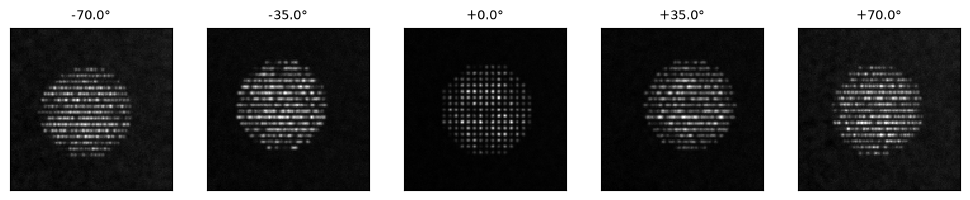

In [4]:
rng = np.random.default_rng(3)
MAX_SHIFT = 6.0                             # 加えるずれの最大値 / largest shift (px)
FILM = 0.02                                 # 支持膜の強さ（粒子の最大値に対して） / film level (relative to the particle peak)
GRAIN = 0.1                                 # 膜のむらの大きさ / film grain (relative to the film level)

true_shift = rng.uniform(-MAX_SHIFT, MAX_SHIFT, (n_tilt, 2))      # (dx, dy) for each tilt
u, v = np.meshgrid(np.linspace(-0.5, 0.5, N), np.linspace(-0.5, 0.5, N), indexing="ij")
gradient = 1 + 0.3 * u + 0.2 * v                                  # 膜の厚さの勾配 / thickness gradient
from scipy.ndimage import gaussian_filter
grain = gaussian_filter(rng.normal(0, 1, (N, N, n_tilt)), (1.5, 1.5, 0))
grain /= grain.std()
film = FILM * clean.max() * (gradient[:, :, None] + GRAIN * grain) / np.cos(np.deg2rad(theta))

raw, _ = add_poisson_noise(shift_images(clean + film, true_shift), counts_per_atom=float(d["counts_per_atom"]), seed=1)
show_projections(raw, theta); plt.show()

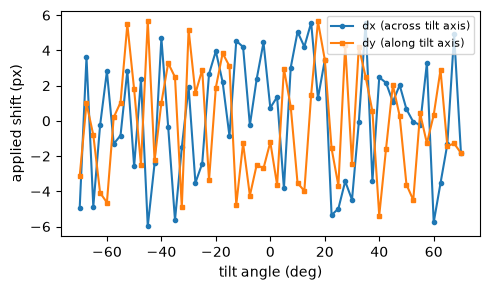

In [5]:
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(theta, true_shift[:, 0], "o-", ms=3, label="dx (across tilt axis)")
ax.plot(theta, true_shift[:, 1], "s-", ms=3, label="dy (along tilt axis)")
ax.set_xlabel("tilt angle (deg)"); ax.set_ylabel("applied shift (px)"); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

## 3. 背景除去 / Background removal

各投影像で粒子の領域を見つけ，その外側の画素に 2 次の曲面を当てはめて背景とします．+70° の像で，元の像・見積もった背景・差し引いた像を比べます．

For each projection the particle region is found, and a quadratic surface fitted to the pixels outside it is taken as the background. Below: the original image, the estimated background and the result at +70°.

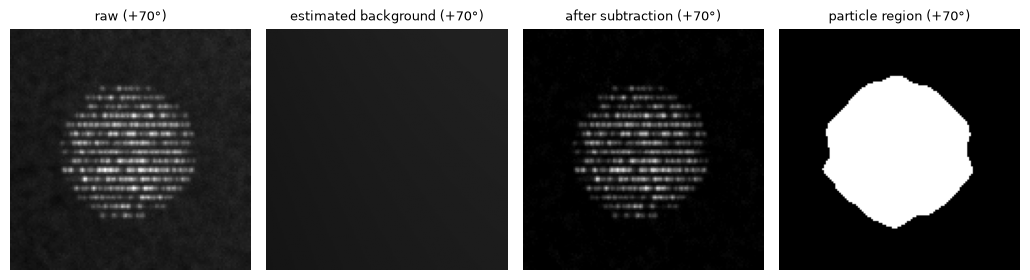

In [6]:
sub, background, masks = subtract_background(raw)
k = n_tilt - 1
lo, hi = 0.0, raw[:, :, k].max()                     # 元の像と差し引いた像は同じ濃淡で表示 / same grey scale
fig, axes = plt.subplots(1, 4, figsize=(10.4, 2.8))
for ax, img, title, rng_ in zip(axes, (raw[:, :, k], background[:, :, k], sub[:, :, k], masks[:, :, k]),
                                ("raw", "estimated background", "after subtraction", "particle region"),
                                ((lo, hi), (lo, hi), (lo, hi), (0, 1))):
    ax.imshow(img.T, origin="lower", cmap="gray", vmin=rng_[0], vmax=rng_[1])
    ax.set_title("%s (%+.0f°)" % (title, theta[k]), fontsize=9); ax.axis("off")
fig.tight_layout(); plt.show()

## 4. 相互相関法による粗い位置合わせ / Coarse alignment by cross-correlation

像を強くぼかして格子の縞を消し，粒子の輪郭どうしを比べます（ぼかさないと，格子 1 周期ぶんずれた位置で一致してしまうことがあります）．全ての像の平均を参照像とし，各像を参照像に重ねる移動量を求め，平均を作り直して数回繰り返します．

The images are blurred strongly to wash out the lattice fringes, so that particle outlines are compared (without blurring, the match can lock one lattice period off). Each image is matched to the mean of all images, the mean is rebuilt, and this is repeated a few times.

In [7]:
coarse = align_cross_correlation(sub)
step1 = shift_images(sub, coarse)

## 5. 共通線法と重心法による精密な位置合わせ / Fine alignment: common line and centre of mass

- **共通線法（y）/ Common line (y)**：y 軸まわりに傾けても，像を x 方向に足し合わせた y 方向の分布（y ごとの試料の総量）はどの角度でも同じです．この分布がそろうように y 方向に動かします．
  For tilts about y, the profile along y obtained by summing an image over x (the total amount of specimen at each y) is the same at every angle. Each image is moved along y until the profiles agree.
- **重心法（x）/ Centre of mass (x)**：各像の重心を回転中心（x = n/2）に合わせます．すべての像で重心がそろうと，試料の三次元の重心が回転軸の上に乗ります．
  Each image is moved so that its centre of mass lies on the rotation centre (x = n/2). When all of them agree, the 3D centre of mass of the specimen sits on the rotation axis.

In [8]:
dy = align_common_line(step1)
step2 = shift_images(step1, np.column_stack([np.zeros(n_tilt), dy]))
dx = align_center_of_mass(step2)
total = coarse + np.column_stack([dx, dy])          # 全体の移動量 / total shift applied
aligned_wide = shift_images(sub, total)

共通線法の前後で，y 方向の分布（共通線）を重ねて表示します．位置合わせの後は全ての角度の分布が重なります．

The y profiles (common lines) of all tilts before and after the common-line step. After alignment they coincide.

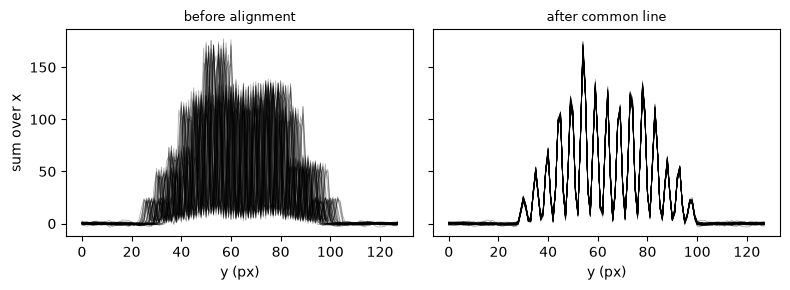

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3), sharey=True)
for ax, stack, title in zip(axes, (sub, step2), ("before alignment", "after common line")):
    ax.plot(stack.sum(axis=0), lw=0.6, color="k", alpha=0.3)
    ax.set_title(title, fontsize=9); ax.set_xlabel("y (px)")
axes[0].set_ylabel("sum over x")
fig.tight_layout(); plt.show()

**サイノグラム**（傾斜軸に垂直な方向 x の分布を，傾斜角の順に並べた像）でも比べます．位置が合うと，粒子の端が角度とともになめらかに変化します．

The same comparison as a **sinogram** (the x profile of each image, stacked by tilt angle). Once aligned, the particle edges change smoothly with the angle.

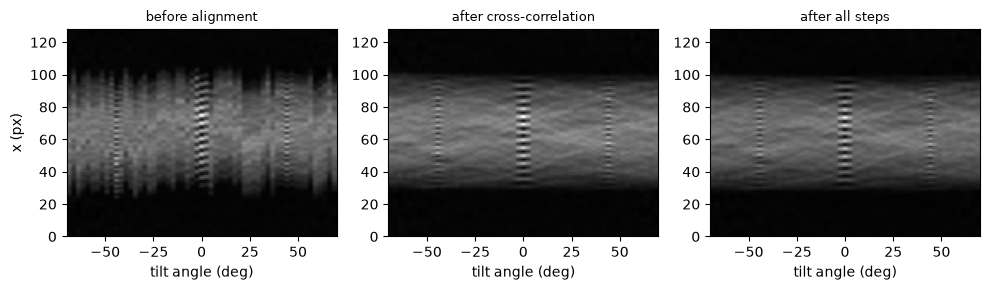

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, stack, title in zip(axes, (sub, step1, aligned_wide),
                            ("before alignment", "after cross-correlation", "after all steps")):
    ax.imshow(stack.sum(axis=1), aspect="auto", cmap="gray", origin="lower",
              extent=(theta[0], theta[-1], 0, N))
    ax.set_title(title, fontsize=9); ax.set_xlabel("tilt angle (deg)")
axes[0].set_ylabel("x (px)")
fig.tight_layout(); plt.show()

## 6. 位置合わせの精度 / How accurate is the alignment?

加えたずれ（正解）と，求めた移動量を比べます．位置合わせで決まらないのは，粒子全体を三次元で平行移動させる成分だけです（x では a cos θ + b sin θ + c，y では一定値）．この成分を除いた残りが位置合わせの誤差です．

The applied (true) shifts are compared with the estimated corrections. The only part alignment cannot determine is a 3D translation of the whole particle (a cos θ + b sin θ + c in x, a constant in y); what remains after removing it is the alignment error.

no alignment       error (rms): x 3.272 px, y 3.107 px
cross-correlation  error (rms): x 0.129 px, y 0.098 px
all steps          error (rms): x 0.090 px, y 0.004 px


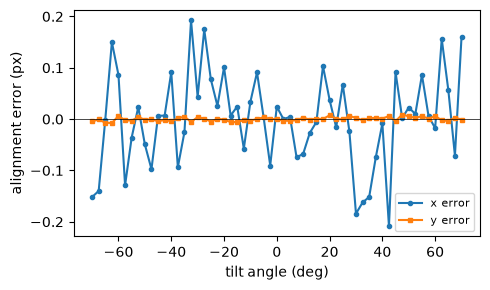

In [11]:
th = np.deg2rad(theta)
A = np.column_stack([np.cos(th), np.sin(th), np.ones(n_tilt)])

def alignment_error(correction):
    e = correction + true_shift                     # 完全なら平行移動の成分だけが残る / only a translation remains if perfect
    ex = e[:, 0] - A @ np.linalg.lstsq(A, e[:, 0], rcond=None)[0]
    ey = e[:, 1] - e[:, 1].mean()
    return ex, ey

for name, corr in (("no alignment", np.zeros_like(true_shift)), ("cross-correlation", coarse), ("all steps", total)):
    ex, ey = alignment_error(corr)
    print("%-18s error (rms): x %.3f px, y %.3f px" % (name, np.sqrt(np.mean(ex**2)), np.sqrt(np.mean(ey**2))))

ex, ey = alignment_error(total)
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(theta, ex, "o-", ms=3, label="x error"); ax.plot(theta, ey, "s-", ms=3, label="y error")
ax.axhline(0, color="k", lw=0.5)
ax.set_xlabel("tilt angle (deg)"); ax.set_ylabel("alignment error (px)"); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

## 7. 再構成への影響 / Effect on the reconstruction

位置合わせなし・相互相関法だけ・全ての前処理の 3 通りで RESIRE（100 回）を行い，原子の抽出の結果を比べます（詳しくは 04, 05 で扱います）．

RESIRE (100 iterations) is run on the data with no alignment, with cross-correlation only, and with all steps, and the traced atoms are compared (details in 04 and 05).

no alignment       found  570 / 959   false  363   RMSD  71.1 pm   species  57.0 %


cross-correlation  found  934 / 959   false    3   RMSD  15.1 pm   species 100.0 %


all steps          found  954 / 959   false    0   RMSD  10.9 pm   species 100.0 %


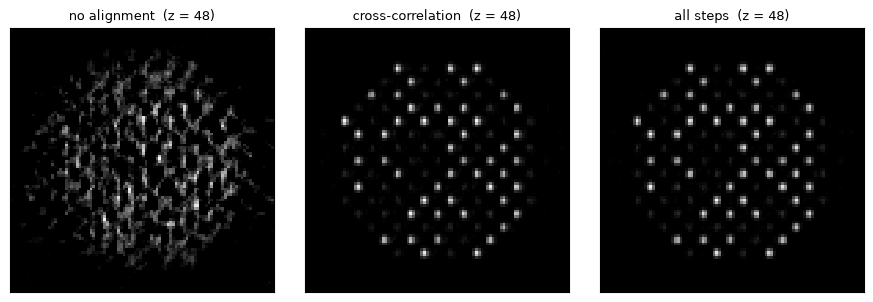

In [12]:
crop = lambda a: a[c0:c0 + n, c0:c0 + n]
nn_px = 3.85 / np.sqrt(2) / pixel_size              # 最近接原子間距離 / nearest-neighbour distance (px)

def quick_check(proj, name):
    b = rs.shift_projections(proj, np.full(n_tilt, -0.5), np.full(n_tilt, -0.5))   # RESIRE の回転中心 / RESIRE's centre (see 04)
    cfg = rs.ReconstructionConfig(num_iterations=100, acceleration="fista", verbose=False)
    vol = rs.reconstruct(b, theta, cfg).reconstruction
    pos, inten = find_atoms(vol, min_distance_px=0.8 * nn_px, threshold=0.03)   # 05 を参照 / see 05
    lab, _, _ = classify_atoms(inten)
    keep = lab >= 0
    m = match_atoms(particle.positions, pos[keep] - (n - 1) / 2, particle.species, lab[keep],
                    tolerance_px=0.5 * nn_px, pixel_size=pixel_size, remove_offset=True)
    print("%-18s found %4d / %d   false %4d   RMSD %5.1f pm   species %5.1f %%"
          % (name, m["found"], len(particle), m["false"], m["rmsd_pm"], 100 * m["species_accuracy"]))
    return vol

vols = {}
vols["no alignment"] = quick_check(crop(sub), "no alignment")
vols["cross-correlation"] = quick_check(crop(step1), "cross-correlation")
vols["all steps"] = quick_check(crop(aligned_wide), "all steps")
show_slices(vols, thickness=3); plt.show()

## 8. 保存 / Save

中央の 96 ピクセルを切り出し，`data/tilt_series_aligned.npz` に保存します．03〜05 のノートブックで `INPUT = "tilt_series_aligned.npz"` とすると，このデータで再構成できます．

The central 96 pixels are cut out and saved to `data/tilt_series_aligned.npz`. Set `INPUT = "tilt_series_aligned.npz"` in notebooks 03–05 to reconstruct these data.

In [13]:
projections = crop(aligned_wide)
np.savez_compressed(DATA / "tilt_series_aligned.npz",
                    projections=projections, theta=theta, true_shift=true_shift, applied_shift=total,
                    positions=particle.positions, species=particle.species,
                    names=np.array(particle.names), amplitudes=np.array(particle.amplitudes),
                    n=n, pixel_size=pixel_size)
print("saved: data/tilt_series_aligned.npz", projections.shape)

saved: data/tilt_series_aligned.npz (96, 96, 57)


### やってみよう / Try it

- `FILM = 0.05` や `0.1` と支持膜を厚くすると，膜のショットノイズのため重心法の精度が下がり，暗い Fe 原子から見落とされるようになります．厚い支持膜が原子分解能のトモグラフィーに不利な理由の一つです．
  Make the film thicker (`FILM = 0.05` or `0.1`). The film's shot noise degrades the centre-of-mass step, and the dim Fe atoms start to be missed: one reason thick support films are bad for atomic-resolution tomography.
- 背景除去をせずに（`sub = raw` として）位置合わせをすると，何が起きるでしょうか．
  What happens if you align without background removal (`sub = raw`)?
- `MAX_SHIFT` を大きくしたり，相互相関法を使わずに共通線法と重心法だけで合わせたりしてみましょう．
  Try a larger `MAX_SHIFT`, or skip the cross-correlation step and use only the common line and centre of mass.

ここで残る 0.1〜0.3 ピクセル程度の誤差は，実際の解析では，再構成から計算した投影像と測定像を比べる位置・角度の精密化（投影マッチング）でさらに小さくします．

The remaining error of about 0.1–0.3 pixel is reduced further in practice by refining the positions and angles against projections calculated from the reconstruction (projection matching).